# Temporal activity and community evolution

This notebook reads a **real completed** chronological Reddit experiment. It
does not fit models, select on test outcomes, invent annotations, or turn an
operational label into social ground truth. Run all five `temporal-study`
stages first. Use the project virtual environment with the graph, research and
notebook extras installed. Historical post-2015 outcome exposure is uncertified.

Five baselines are Majority, Persistence, flat dynamic LR, hierarchical static
HGB and hierarchical dynamic HGB. They accompany the original proposed
hierarchical dynamic LR and one matched no-dynamics ablation. Four tuned
families use 192 configuration-fold evaluations (two-head models fit up to two
estimators each). HGB dynamic was an alternative architecture in the original
run; its reference role here is retrospective.
This is a post-evaluation presentation reduction, not a new independent run.
The reader verifies all original frozen predictions before projecting to seven
methods, retains the original primary/champion, and requires the original
champion interval to remain unchanged. The secondary strongest-reference
interval is reported separately.

In [1]:
# Find the project from either its root or notebooks/core. Use the installed
# package; never patch sys.path or select an unrelated global interpreter.
from pathlib import Path
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
project = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
run = project / "artifacts/temporal/activity-study-001"
from reddit_sna.reporting.temporal_study import read_compact_study, study_figures, study_diagnostics
data = read_compact_study(run)
display(Markdown("Prediction inventories and independently recomputed metrics verified."))

Prediction inventories and independently recomputed metrics verified.

## Problem, graph and target

The input is a detected user community at the end of month *t*. The output is
its next-month observed structural event. Reply edges connect comment author
to parent author; the undirected Leiden graph sums both directions. Subreddit
is context, not a labeled community. GED-adapted labels are tracker-derived:
stable means equal size on a one-to-one link; dissolve is loss of meaningful
observed inclusion, not proof of social disappearance. Final snapshots are
censored. Unresolved transitions remain in coverage reporting.

In [2]:
# Describe the measured population and preserve every support/exclusion count.
display(Markdown("### Measurement audit"))
display(data["label_audit"])
display(Markdown("### Exposure and remaining human review"))
display(data["exposure"])
display(Markdown("Human annotation and novelty verification remain pending."))

### Measurement audit

{'status': 'automated_rule_consistency_verified',
 'support': {'split': 166,
  'dissolve': 6867,
  'unresolved': 4072,
  'grow': 87,
  'merge': 229,
  'shrink': 125,
  'stable': 16},
 'reasons': {'multiple_successors': 166,
  'below_dissolve_threshold': 6867,
  'weak_overlap_unresolved': 4072,
  'one_to_one_size_comparison': 228,
  'multiple_predecessors': 229,
  'final_snapshot_censored': 183},
 'size_strata': {'split:size_ge10': 166,
  'dissolve:size_ge10': 277,
  'unresolved:size_le2': 2770,
  'dissolve:size_le2': 4576,
  'dissolve:size_3to9': 2014,
  'grow:size_le2': 66,
  'merge:size_le2': 153,
  'unresolved:size_3to9': 1018,
  'unresolved:size_ge10': 284,
  'merge:size_3to9': 76,
  'shrink:size_ge10': 114,
  'grow:size_3to9': 21,
  'stable:size_3to9': 1,
  'shrink:size_3to9': 11,
  'stable:size_le2': 15},
 'human_review': 'pending',
 'target': 'GED-adapted observed structural events, not social ground truth',
 'stable': 'equal size on accepted one-to-one link; membership may diff

### Exposure and remaining human review

{'known': '2015 forecasts and full-period aggregate inventory inspected',
 'previous_post2015_forecast_exposure': 'not independently established',
 'unseen': False}

Human annotation and novelty verification remain pending.

In [3]:
# Primary method and baseline champion were chosen before final evaluation.
# Keep the strongest realized baseline visible even if it defeats proposed.
result = data["evaluation"]
table = "| Model | Fixed-six-class Macro-F1 |\n|---|---:|\n"
table += "\n".join(f"| {name} | {value:.4f} |" for name, value in
                   sorted(result["mean_macro_f1"].items(), key=lambda item: -item[1]))
display(Markdown(table))
display(study_diagnostics(data))
display({key: result[key] for key in ("proposed", "validation_selected_champion",
    "strongest_realized_baseline", "delta_vs_strongest", "intervals", "superiority")})

| Model | Fixed-six-class Macro-F1 |
|---|---:|
| hier_lr_dynamic | 0.4117 |
| hier_hgb_dynamic | 0.3880 |
| hier_hgb_static | 0.3728 |
| A_no_dynamics_matched | 0.3643 |
| flat_lr_dynamic | 0.3616 |
| B1_majority | 0.1597 |
| B1_persistence | 0.1562 |

{'strongest_reference': 'hier_hgb_dynamic',
 'secondary_interval': {'low': -0.08279976887233198,
  'high': 0.0983841175983789,
  'draws': 2000,
  'block_length': 3,
  'scope': 'paired exploratory monthly blocks; pseudo-label validity separate'},
 'secondary_superiority': 'not_demonstrated',
 'per_class': {'hier_lr_dynamic': [{'label': 'stable',
    'support': 4,
    'f1': 0.0},
   {'label': 'grow', 'support': 19, 'f1': 0.09677419354838708},
   {'label': 'shrink', 'support': 25, 'f1': 0.4444444444444444},
   {'label': 'merge', 'support': 15, 'f1': 0.23076923076923075},
   {'label': 'split', 'support': 39, 'f1': 0.7397260273972602},
   {'label': 'dissolve', 'support': 1167, 'f1': 0.9587136027813994}],
  'hier_hgb_dynamic': [{'label': 'stable', 'support': 4, 'f1': 0.0},
   {'label': 'grow', 'support': 19, 'f1': 0.1276595744680851},
   {'label': 'shrink', 'support': 25, 'f1': 0.4666666666666666},
   {'label': 'merge', 'support': 15, 'f1': 0.11320754716981134},
   {'label': 'split', 'suppor

{'proposed': 'hier_lr_dynamic',
 'validation_selected_champion': 'hier_hgb_static',
 'strongest_realized_baseline': 'hier_hgb_dynamic',
 'delta_vs_strongest': 0.023692458771724823,
 'intervals': {'hier_hgb_static': {'low': 0.005616971178524999,
   'high': 0.07444987582713058,
   'draws': 2000,
   'block_length': 3,
   'scope': 'paired exploratory monthly blocks; pseudo-label validity separate'}},
 'superiority': 'supported_on_this_operational_target'}

### Comparison

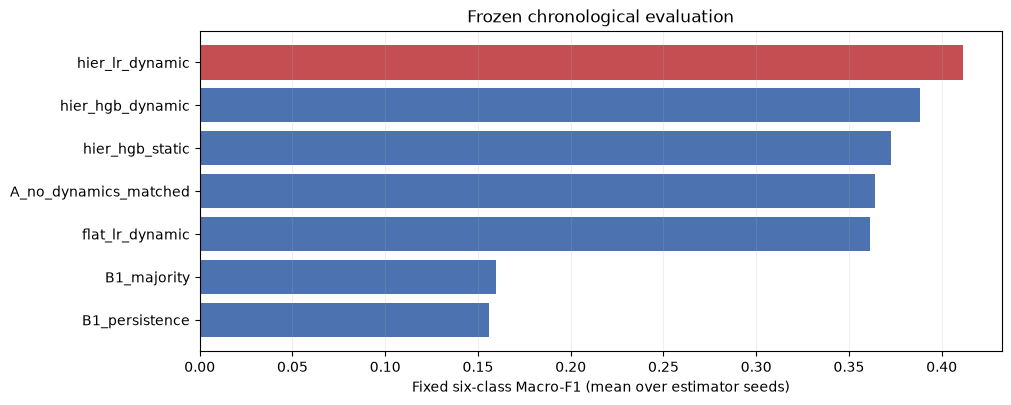

### Monthly

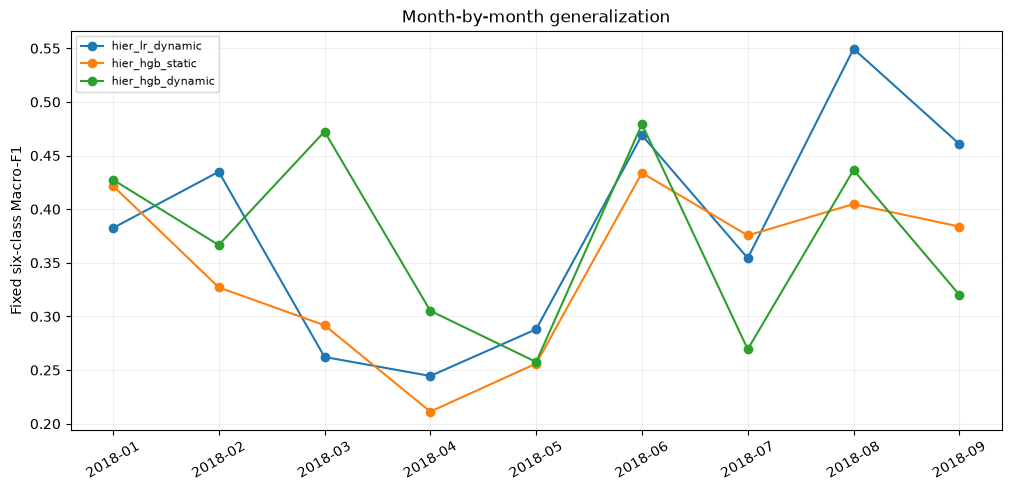

### Support

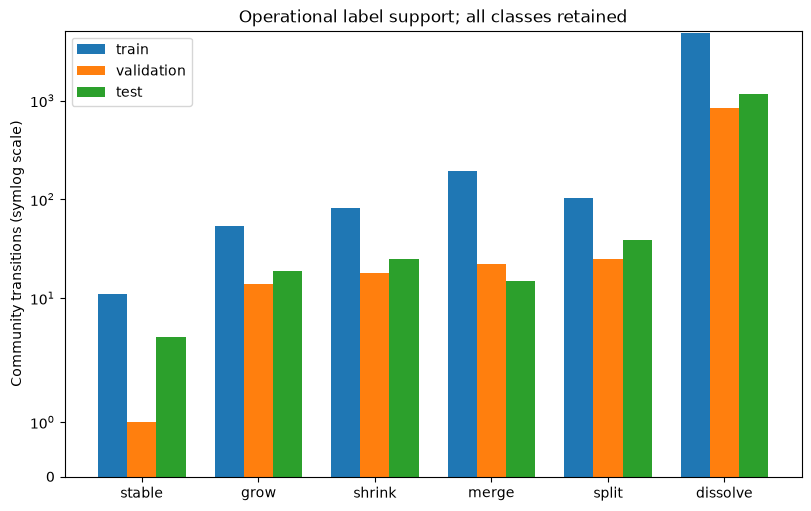

### Confusion

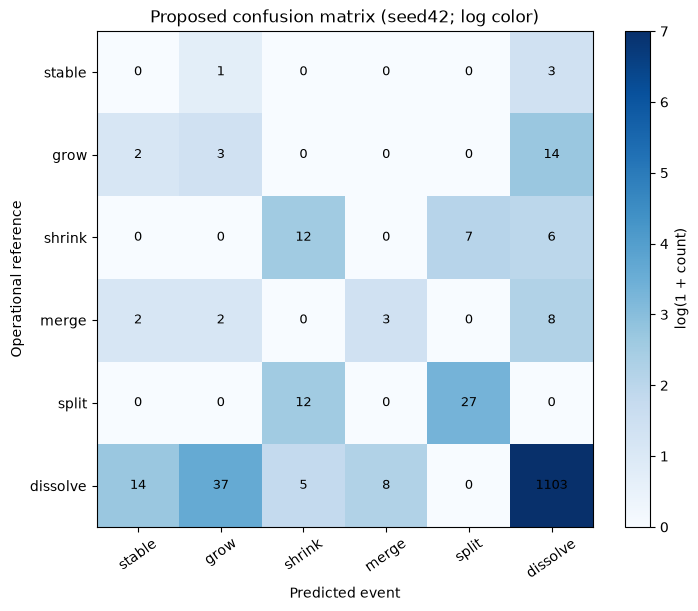

### Flow

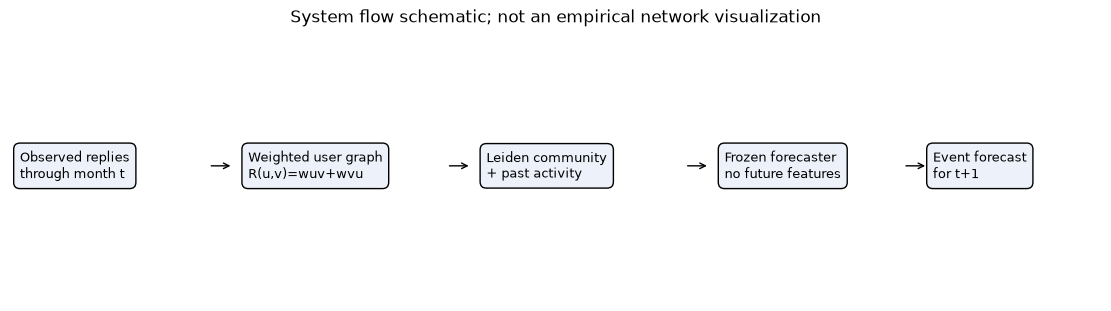

### Graph Scale

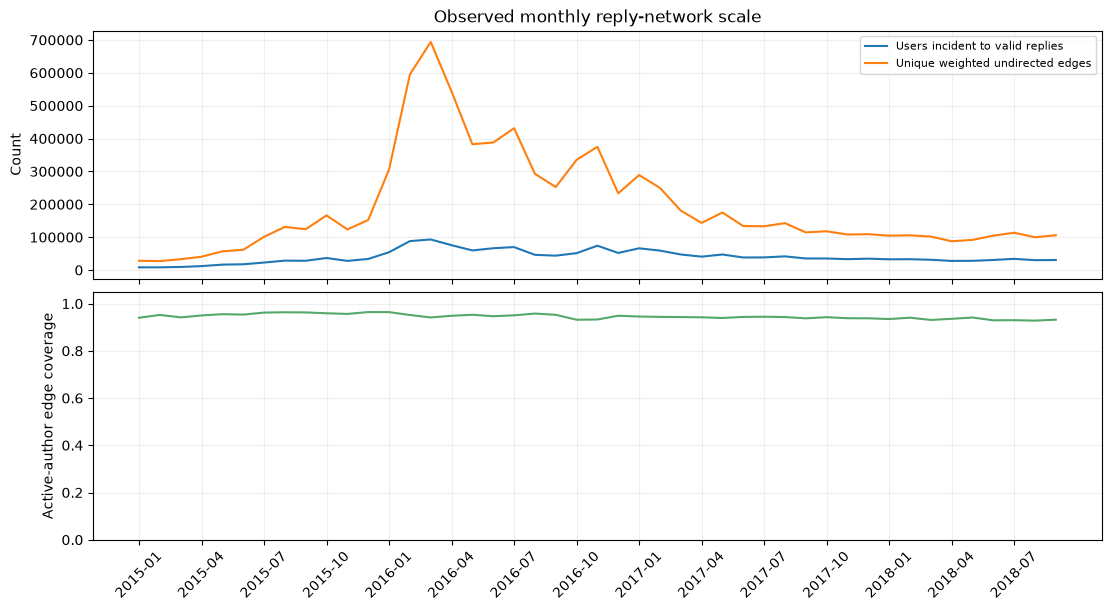

### Community Graph

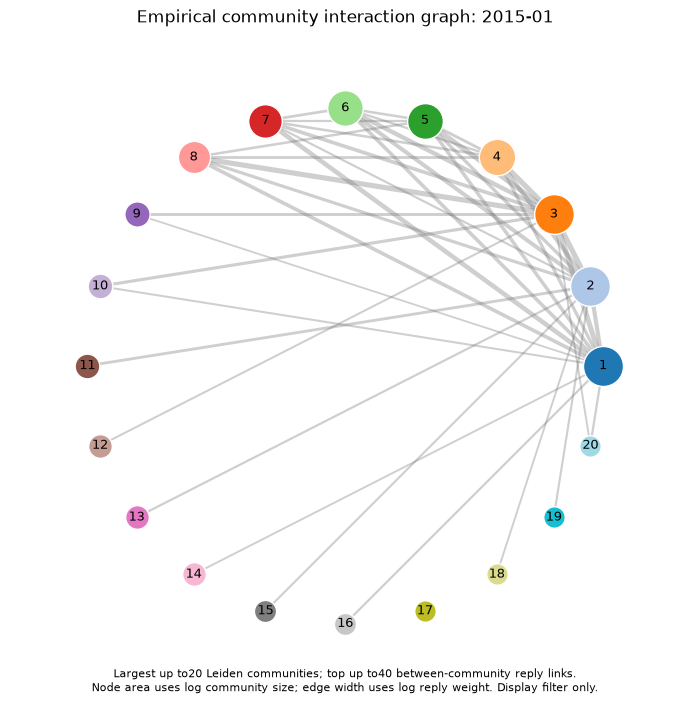

In [4]:
# Show real comparison, monthly generalization, class support and confusion.
# The flow chart is explicitly a schematic, not measured network evidence.
figures = study_figures(data)
for name, figure in figures.items():
    display(Markdown(f"### {name.replace('_', ' ').title()}"))
    display(figure)
    plt.close(figure)

## Interpretation

Compare the primary proposed method with both the validation-selected champion
and every stronger realized fair baseline. The matched no-dynamics ablation tests dynamic features at fixed settings.
The independently tuned flat LR uses the same inputs to assess hierarchy. Fixed-six-class F1
retains absent classes; read class support, size strata, unresolved coverage and
per-month performance alongside its aggregate. Block intervals use months, not
estimator seeds, as the resampling unit. A failed superiority criterion remains
a negative finding and does not authorize another search on these test labels.

Sources: [ConvoKit corpus](https://convokit.cornell.edu/documentation/subreddit.html),
[GED](https://doi.org/10.1007/s13278-012-0058-8),
[Leiden](https://doi.org/10.1038/s41598-019-41695-z),
[temporal evaluation](https://scikit-learn.org/stable/modules/cross_validation.html).